# Autoregressive Image Transformer on MNIST

This notebook carries the ring autoregressive sequence into dynamically binarized MNIST with a strong, modern **causal image Transformer**, using global causal self-attention and key/value caching during generation.

### Learning goals
1. Express image density with the probability chain rule.
2. Train all next-pixel conditionals in parallel with a causal mask.
3. Generate sequentially while caching Transformer states.
4. Evaluate exact likelihood and prefix completion.
5. Make the central trade-off visible: flexible exact density versus sequential sampling.

> **Execution note:** Representative outputs are embedded below. **Run modes:** `RUN_MODE = "lecture"` (the default) loads the bundled checkpoint and avoids retraining. Use `"full"` to train the documented configuration, or `"smoke"` for a reduced CPU pipeline check. Smoke-mode checkpoints and results are deliberately separate and are **not** representative model results.

## Before you begin

**Prerequisites.** Know the probability chain rule, Bernoulli likelihood, causal masking, and the query/key/value view of self-attention. Notebook 03 (the ring autoregressive model) is the conceptual predecessor.

> **Notation and orientation**
> - The image becomes a raster sequence $x_{1:L}$ with $L=784$. A token $x_i$ is predicted only from $x_{<i}$.
> - **Unchanged from the ring:** normalized likelihood and ancestral factorization.
> - **New at image scale:** a long, ordered pixel sequence, masked self-attention, dynamic binarization, and a key/value cache for generation.

## 1. Setup and configuration

The model uses mixed precision when CUDA is available. The default size is intentionally large enough to demonstrate coherent generation.

The explicit smoke mode reduces the dataset, model width/depth, and epochs for a CPU pipeline check. Its results are not representative.


In [1]:
import gzip
import math
import random
import struct
import time
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 7
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN_MEMORY = DEVICE.type == "cuda"

RUN_MODE = "lecture"  # "lecture", "full", or "smoke"
if RUN_MODE not in {"lecture", "full", "smoke"}:
    raise ValueError("RUN_MODE must be 'lecture', 'full', or 'smoke'.")
TRAIN = RUN_MODE != "lecture"
EPOCHS = 1 if RUN_MODE == "smoke" else 40
BATCH_SIZE = 128
D_MODEL = 64 if RUN_MODE == "smoke" else 256
N_HEADS = 4 if RUN_MODE == "smoke" else 8
N_LAYERS = 2 if RUN_MODE == "smoke" else 8
DROPOUT = 0.1
LEARNING_RATE = 3e-4
NOTEBOOK_DIR = Path("notebooks") if Path("notebooks").is_dir() else Path(".")
checkpoint_name = "image_transformer_mnist_smoke.pt" if RUN_MODE == "smoke" else "image_transformer_mnist.pt"
CHECKPOINT = NOTEBOOK_DIR / "checkpoints" / checkpoint_name
CHECKPOINT.parent.mkdir(parents=True, exist_ok=True)
PLOT_THEME = "light"  # Change to "dark" for the dark plot palette.
if PLOT_THEME not in {"light", "dark"}:
    raise ValueError("PLOT_THEME must be 'light' or 'dark'.")

# Start from Matplotlib defaults so light mode keeps the standard coloring.
plt.style.use("default")
if PLOT_THEME == "dark":
    plt.style.use("dark_background")
    plt.rcParams.update(
        {
            "figure.facecolor": "#0a0f18",
            "figure.edgecolor": "#0a0f18",
            "axes.facecolor": "#111926",
            "axes.edgecolor": "#e8eff9",
            "axes.labelcolor": "#e8eff9",
            "axes.titlecolor": "#e8eff9",
            "text.color": "#e8eff9",
            "xtick.color": "#e8eff9",
            "ytick.color": "#e8eff9",
            "grid.color": "#2b3340",
            "savefig.facecolor": "#0a0f18",
            "savefig.edgecolor": "#0a0f18",
        }
    )

PLOT_REFERENCE_COLOR = "black" if PLOT_THEME == "light" else "#6cd2e8"
PLOT_GENERATED_COLOR = "tab:orange" if PLOT_THEME == "light" else "#f09a4b"
PLOT_GUIDE_COLOR = "black" if PLOT_THEME == "light" else "#e8eff9"

plt.rcParams.update({"figure.figsize": (7, 5), "axes.grid": False, "font.size": 11})
print(f"PyTorch {torch.__version__} | device: {DEVICE} | run mode: {RUN_MODE}")
if RUN_MODE == "smoke":
    print("SMOKE MODE: reduced-cost pipeline check; results are not representative.")

PyTorch 2.12.0+cu130 | device: cuda | run mode: lecture


## 2. Data and dynamic binarization

For grayscale intensity $g_i\in[0,1]$, dynamic binarization samples

$$x_i\sim\operatorname{Bernoulli}(g_i).$$

This gives a well-defined binary image distribution with one Bernoulli conditional per pixel. The labels are retained here only for post-training likelihood analysis.

In [2]:
DATA_DIR = NOTEBOOK_DIR / "data/mnist"
DATA_DIR.mkdir(parents=True, exist_ok=True)
BASE_URL = "https://storage.googleapis.com/cvdf-datasets/mnist/"
FILES = {
    "train_images": "train-images-idx3-ubyte.gz",
    "train_labels": "train-labels-idx1-ubyte.gz",
    "test_images": "t10k-images-idx3-ubyte.gz",
    "test_labels": "t10k-labels-idx1-ubyte.gz",
}
for filename in FILES.values():
    destination = DATA_DIR / filename
    if not destination.exists():
        urlretrieve(BASE_URL + filename, destination)


def read_images(path):
    with gzip.open(path, "rb") as f:
        magic, n, h, w = struct.unpack(">IIII", f.read(16))
        assert magic == 2051
        data = np.frombuffer(f.read(), dtype=np.uint8).copy()
    return torch.from_numpy(data.reshape(n, 1, h, w)).float() / 255


def read_labels(path):
    with gzip.open(path, "rb") as f:
        magic, n = struct.unpack(">II", f.read(8))
        assert magic == 2049
        data = np.frombuffer(f.read(), dtype=np.uint8).copy()
    return torch.from_numpy(data.astype(np.int64))


x_train = read_images(DATA_DIR / FILES["train_images"])
y_train = read_labels(DATA_DIR / FILES["train_labels"])
x_test = read_images(DATA_DIR / FILES["test_images"])
y_test = read_labels(DATA_DIR / FILES["test_labels"])
train_count = len(x_train) if RUN_MODE != "smoke" else min(2_048, len(x_train))
train_dataset = TensorDataset(x_train[:train_count], y_train[:train_count])
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    pin_memory=PIN_MEMORY,
    generator=torch.Generator().manual_seed(SEED),
)
test_loader = DataLoader(
    TensorDataset(x_test, y_test), batch_size=256, shuffle=False, pin_memory=PIN_MEMORY
)
print(tuple(x_train.shape), tuple(x_test.shape))

(60000, 1, 28, 28) (10000, 1, 28, 28)


In [3]:
def show_image_grid(images, nrow=10, title=None, value_range=(0, 1)):
    images = images.detach().cpu()
    images = images[:, 0] if images.ndim == 4 else images
    ncol = int(np.ceil(len(images) / nrow))
    canvas = torch.ones(ncol * 28 + ncol - 1, nrow * 28 + nrow - 1)
    for i, image in enumerate(images):
        r, col = divmod(i, nrow)
        canvas[r * 29 : r * 29 + 28, col * 29 : col * 29 + 28] = image
    fig, ax = plt.subplots(figsize=(nrow, ncol))
    ax.imshow(canvas, cmap="gray", vmin=value_range[0], vmax=value_range[1])
    ax.axis("off")
    if title:
        ax.set_title(title)
    plt.tight_layout()
    plt.show()

## 3. Shifted-token factorization

Flatten each image in raster order to $x_1,\ldots,x_{784}$. The model receives

$$[\text{BOS},x_1,x_2,\ldots,x_{783}]$$

and predicts

$$[x_1,x_2,\ldots,x_{784}].$$

A causal attention mask ensures position $i$ sees only preceding input tokens. Unlike a local PixelCNN, every prediction can attend directly to the entire available prefix.

## 4. Cached causal Transformer

During training, all positions are processed in parallel. During generation, pixels remain sequential, but each layer caches previous keys and values. This avoids recomputing the complete prefix at every step, reducing naive quadratic repeated work.

Two-dimensional row and column embeddings preserve image geometry in addition to sequence order.

In [4]:
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.output = nn.Linear(d_model, d_model)
        self.dropout = dropout

    def split(self, x):
        return x.view(len(x), x.shape[1], self.n_heads, self.head_dim).transpose(1, 2)

    def forward(self, x, cache=None):
        q, k, v = self.qkv(x).chunk(3, -1)
        q, k, v = self.split(q), self.split(k), self.split(v)
        if cache is None:
            output = F.scaled_dot_product_attention(
                q,
                k,
                v,
                attn_mask=None,
                dropout_p=self.dropout if self.training else 0,
                is_causal=True,
            )
            new_cache = (k, v)
        else:
            previous_k, previous_v = cache
            k = torch.cat([previous_k, k], 2)
            v = torch.cat([previous_v, v], 2)
            output = F.scaled_dot_product_attention(
                q, k, v, attn_mask=None, dropout_p=0, is_causal=False
            )
            new_cache = (k, v)
        output = output.transpose(1, 2).contiguous().view(len(x), x.shape[1], -1)
        return self.output(output), new_cache


class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, dropout):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.attention = CausalSelfAttention(d_model, n_heads, dropout)
        self.norm2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(4 * d_model, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x, cache=None):
        attended, new_cache = self.attention(self.norm1(x), cache)
        x = x + attended
        x = x + self.mlp(self.norm2(x))
        return x, new_cache


class ImageTransformer(nn.Module):
    def __init__(self, d_model=256, n_heads=8, n_layers=8, dropout=0.1):
        super().__init__()
        self.token_embedding = nn.Embedding(3, d_model)  # 0, 1, and BOS=2
        self.row_embedding = nn.Embedding(28, d_model)
        self.column_embedding = nn.Embedding(28, d_model)
        self.dropout = nn.Dropout(dropout)
        self.blocks = nn.ModuleList(
            [TransformerBlock(d_model, n_heads, dropout) for _ in range(n_layers)]
        )
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, 1)

    def positions(self, start, length, device):
        indices = torch.arange(start, start + length, device=device)
        return self.row_embedding(indices // 28) + self.column_embedding(indices % 28)

    def forward(self, input_tokens):
        x = self.dropout(
            self.token_embedding(input_tokens)
            + self.positions(0, input_tokens.shape[1], input_tokens.device)[None]
        )
        for block in self.blocks:
            x, _ = block(x)
        return self.head(self.norm(x)).squeeze(-1)

    def step(self, token, position, caches):
        x = (
            self.token_embedding(token)
            + self.positions(position, 1, token.device)[None]
        )
        new = []
        for block, cache in zip(self.blocks, caches):
            x, updated = block(x, cache)
            new.append(updated)
        return self.head(self.norm(x)).squeeze(-1), new


def shifted_tokens(binary_images):
    targets = binary_images.flatten(1).long()
    bos = torch.full((len(targets), 1), 2, device=targets.device, dtype=torch.long)
    return torch.cat([bos, targets[:, :-1]], 1), targets


model = ImageTransformer(D_MODEL, N_HEADS, N_LAYERS, DROPOUT).to(DEVICE)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Parameters: 6,333,953


## 5. Causality test

Changing one target pixel may influence later logits but must not influence its own or earlier predictions. This is the Transformer analogue of testing a PixelCNN mask.

### Predict before running

> **Commit to a prediction:** if only future raster positions are changed, should logits for an unchanged prefix move? State the expected numerical result and justify it from the causal mask.

In [5]:
model.eval()
base = torch.zeros(1, 1, 28, 28, device=DEVICE)
changed = base.clone()
changed[:, :, 14, 14] = 1
input_a, _ = shifted_tokens(base)
input_b, _ = shifted_tokens(changed)
with torch.no_grad():
    difference = (model(input_a) - model(input_b)).abs()[0]
index = 14 * 28 + 14
print(
    f"Earlier/current effect: {difference[:index+1].max().item():.2e} | later effect: {difference[index+1:].max().item():.2e}"
)
assert difference[: index + 1].max() < 1e-7 and difference[index + 1 :].max() > 0

Earlier/current effect: 0.00e+00 | later effect: 3.42e-01


> **Expected observation / interpretation.** Prefix logits should agree up to numerical precision. Any substantial change would reveal information leakage from future pixels and invalidate the autoregressive likelihood.

## 6. Exact maximum-likelihood training

Teacher forcing evaluates all 784 normalized Bernoulli conditionals in parallel. The learning-rate schedule combines linear warm-up with cosine decay. Checkpoints make the expensive training run reusable.

In [6]:
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, betas=(0.9, 0.95), weight_decay=0.01
)
total_steps = EPOCHS * len(train_loader)
warmup_steps = min(2000, total_steps // 10)


def lr_factor(step):
    if step < warmup_steps:
        return (step + 1) / max(1, warmup_steps)
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + math.cos(math.pi * progress))


scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")
history = []
global_step = 0

if not TRAIN:
    checkpoint = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model"])
    history = checkpoint["history"]
    print(f"Loaded {CHECKPOINT}")
else:
    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_nll = 0
        for grayscale, _ in train_loader:
            binary = torch.bernoulli(grayscale.to(DEVICE, non_blocking=True))
            inputs, targets = shifted_tokens(binary)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=DEVICE.type == "cuda",
            ):
                logits = model(inputs)
                nll = F.binary_cross_entropy_with_logits(
                    logits, targets.float(), reduction="none"
                ).sum(1)
                loss = nll.mean()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            global_step += 1
            total_nll += nll.detach().sum().item()
        bpd = total_nll / (len(train_loader) * BATCH_SIZE * 784 * math.log(2))
        history.append(bpd)
        print(f"epoch {epoch:3d}/{EPOCHS} | {bpd:.4f} bits/dim")
        torch.save(
            {"model": model.state_dict(), "history": history, "epoch": epoch},
            CHECKPOINT,
        )

Loaded checkpoints/image_transformer_mnist.pt


## 7. Likelihood and conditional uncertainty

The model provides exact normalized binary-image likelihoods. Hence, we can use probability and entropy maps to show where the next pixel is predictable from its prefix and where several continuations remain plausible.

Thresholded test likelihood: 0.1109 bits/dim


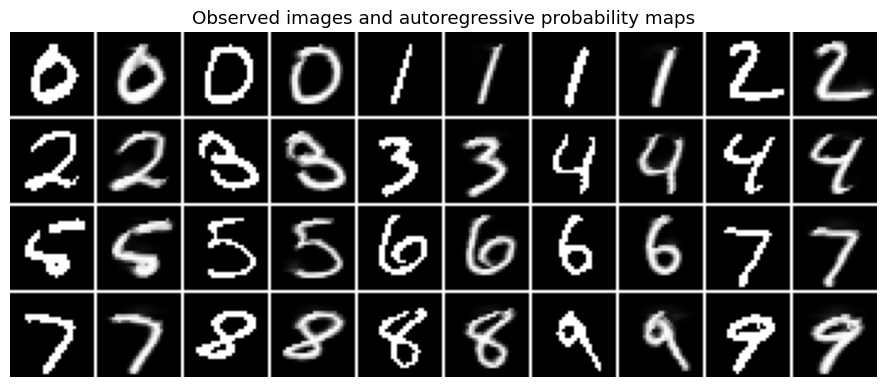

In [7]:
model.eval()
test_binary = (x_test >= 0.5).float()
total = 0

with torch.no_grad():
    for start in range(0, len(test_binary), 256):
        batch = test_binary[start : start + 256].to(DEVICE)
        inputs, targets = shifted_tokens(batch)
        logits = model(inputs)
        total += F.binary_cross_entropy_with_logits(
            logits, targets.float(), reduction="sum"
        ).item()
print(
    f"Thresholded test likelihood: {total/(len(test_binary)*784*math.log(2)):.4f} bits/dim"
)

indices = torch.cat([torch.where(y_test == d)[0][:2] for d in range(10)])
observed = test_binary[indices].to(DEVICE)
inputs, _ = shifted_tokens(observed)
with torch.no_grad():
    probabilities = model(inputs).sigmoid().reshape(-1, 1, 28, 28).cpu()
paired = torch.stack([observed.cpu(), probabilities], 1).reshape(-1, 1, 28, 28)
show_image_grid(paired, 10, "Observed images and autoregressive probability maps")

## 8. Cached ancestral sampling

Sampling remains sequential over 784 pixels but cached attention avoids repeatedly encoding the entire prefix. Generation temperature modifies logits before Bernoulli sampling.

100 cached ancestral samples: 5.75 s


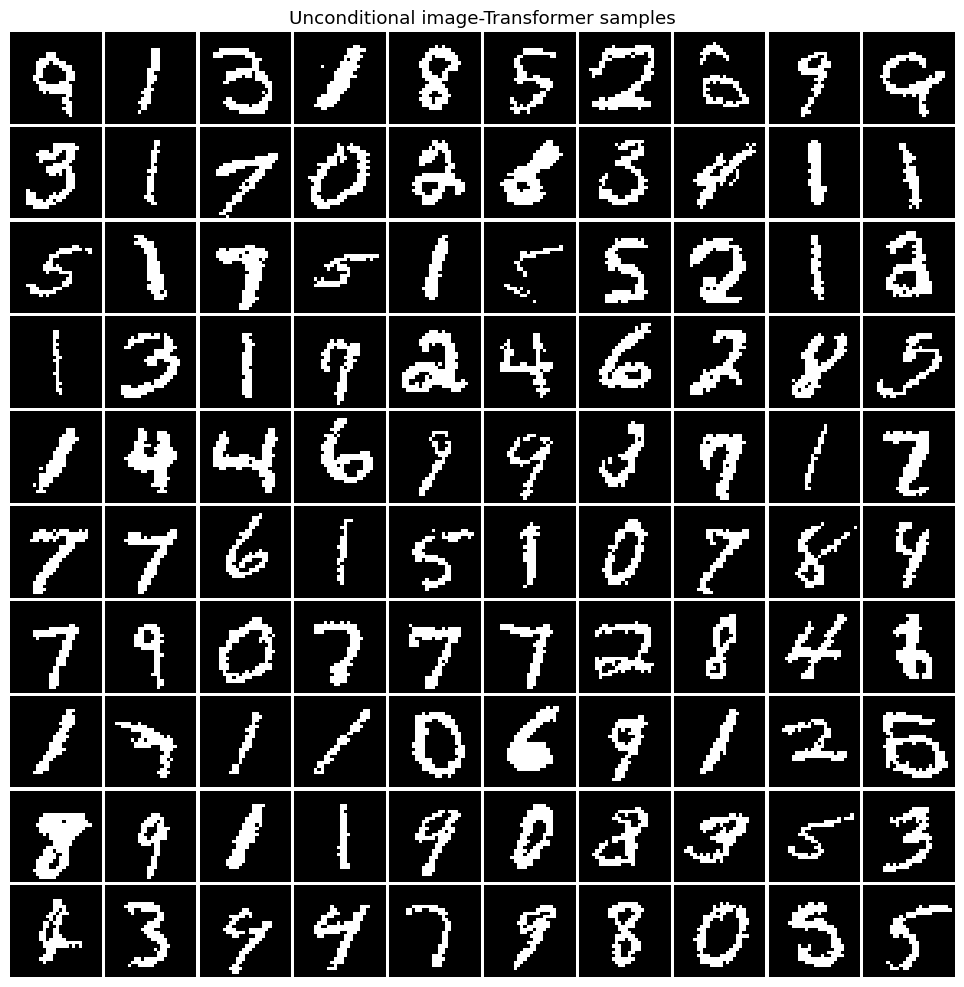

In [8]:
@torch.no_grad()
def sample(model, n, temperature=1.0, prefix=None, prefix_length=0, snapshots=()):
    model.eval()
    device = next(model.parameters()).device
    caches = [None] * len(model.blocks)
    token = torch.full((n, 1), 2, device=device, dtype=torch.long)
    pixels = []
    saved = {}
    prefix_flat = None if prefix is None else prefix.to(device).flatten(1).long()
    for position in range(784):
        logits, caches = model.step(token, position, caches)
        probability = torch.sigmoid(logits[:, 0] / temperature)
        pixel = (
            prefix_flat[:, position]
            if prefix_flat is not None and position < prefix_length
            else torch.bernoulli(probability).long()
        )
        pixels.append(pixel)
        token = pixel[:, None]
        if position + 1 in snapshots:
            saved[position + 1] = torch.stack(pixels, 1).reshape(n, 1, -1).cpu()
    images = torch.stack(pixels, 1).reshape(n, 1, 28, 28).float().cpu()
    return images, saved


start = time.perf_counter()
generated, snapshots = sample(
    model, 100, temperature=1.0, snapshots=(196, 392, 588, 784)
)
print(f"100 cached ancestral samples: {time.perf_counter()-start:.2f} s")
show_image_grid(generated, 10, "Unconditional image-Transformer samples")

## 9. Prefix completion and generation order

The first 14 rows form a valid raster-order prefix. Multiple lower-half samples visualize conditional uncertainty. Arbitrary-hole inpainting is not native to this fixed factorization.

### Predict before running

>**Commit to a prediction:** which rows of a half-image prefix completion should remain fixed, and why can the missing suffix not be generated in one parallel pass? Justify using the factorization order.

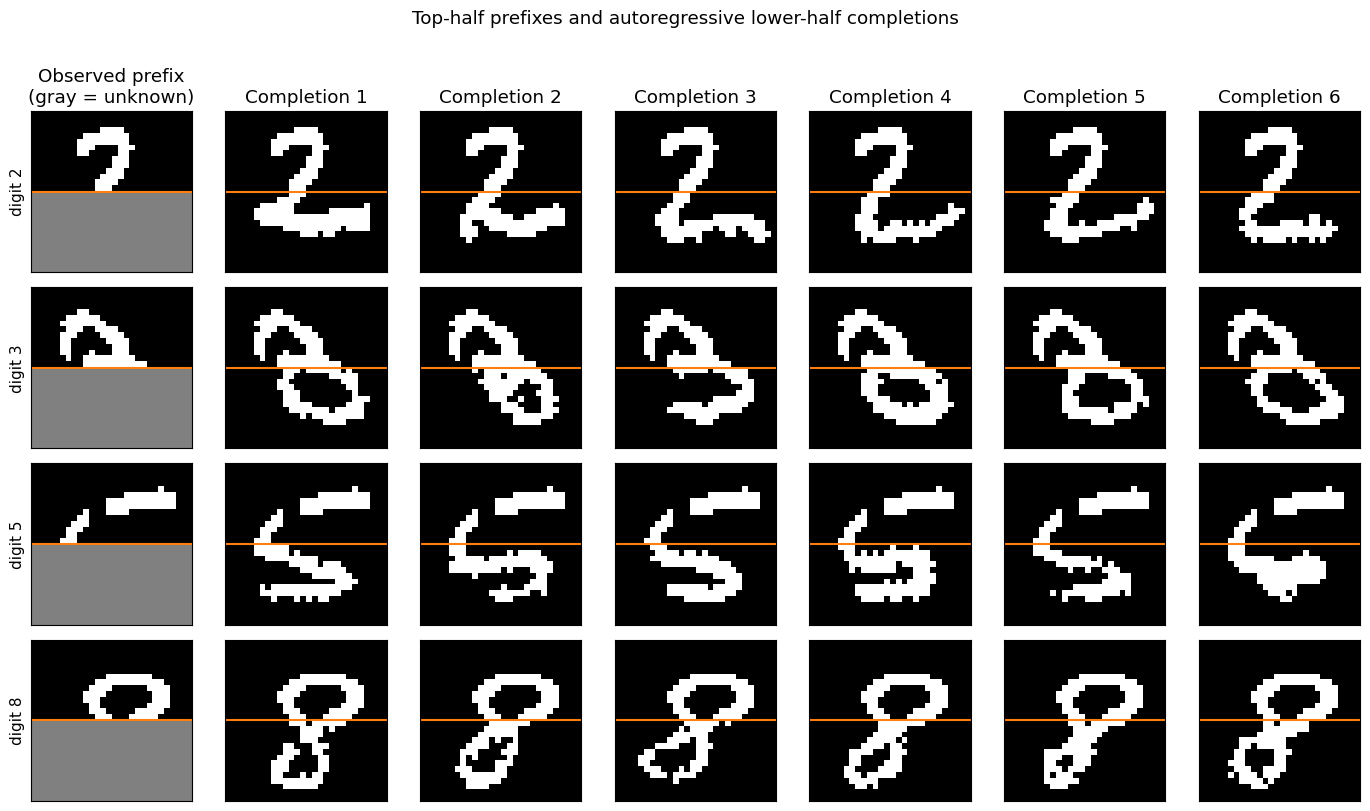

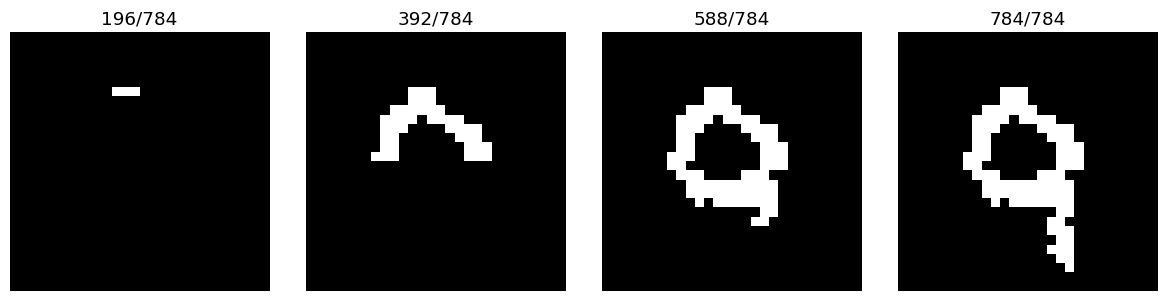

In [9]:
digits = [2, 3, 5, 8]
n_completions = 6
prefix_rows = 14
prefix_length = prefix_rows * 28

prefix_indices = torch.tensor(
    [int(torch.where(y_test == digit)[0][0]) for digit in digits]
)
source_images = test_binary[prefix_indices]
prefix_batch = source_images.repeat_interleave(n_completions, dim=0)
completions, _ = sample(
    model,
    len(prefix_batch),
    prefix=prefix_batch,
    prefix_length=prefix_length,
)
completions = completions.reshape(len(digits), n_completions, 1, 28, 28)

# Show exactly what the model observes, followed by several conditional samples.
# Gray pixels in the first column are unknown; they are generated left-to-right,
# top-to-bottom in the completion columns.
prefix_display = source_images.clone()
prefix_display[:, :, prefix_rows:, :] = torch.nan
gray_with_unknown = plt.colormaps["gray"].copy()
gray_with_unknown.set_bad("#808080")

fig, axes = plt.subplots(
    len(digits),
    n_completions + 1,
    figsize=(2 * (n_completions + 1), 2 * len(digits)),
    squeeze=False,
)
for row, digit in enumerate(digits):
    axes[row, 0].imshow(
        prefix_display[row, 0], cmap=gray_with_unknown, vmin=0, vmax=1
    )
    axes[row, 0].set_ylabel(f"digit {digit}", fontsize=11)
    for sample_index in range(n_completions):
        axes[row, sample_index + 1].imshow(
            completions[row, sample_index, 0], cmap="gray", vmin=0, vmax=1
        )
    for ax in axes[row]:
        ax.axhline(prefix_rows - 0.5, color="tab:orange", linewidth=1.5)
        ax.set_xticks([])
        ax.set_yticks([])

axes[0, 0].set_title("Observed prefix\n(gray = unknown)")
for sample_index in range(n_completions):
    axes[0, sample_index + 1].set_title(f"Completion {sample_index + 1}")
fig.suptitle("Top-half prefixes and autoregressive lower-half completions", y=1.01)
plt.tight_layout()
plt.show()

steps = [196, 392, 588, 784]
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, step in zip(axes, steps):
    partial = torch.zeros(784)
    partial[:step] = snapshots[step][0, 0, :step]
    ax.imshow(partial.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{step}/784")
    ax.axis("off")
plt.tight_layout()
plt.show()

>**Expected observation / interpretation.** The observed prefix is copied exactly while the suffix varies conditionally. Each new pixel becomes context for the next, so exact sampling remains sequential over the unobserved positions even though teacher-forced training is parallel.

## 10. Likelihood by class and sampling temperature

Labels are used only after evaluation. Class-wise likelihood reveals which writing structures are easiest under raster order. Temperature demonstrates the sharpness–diversity trade-off.

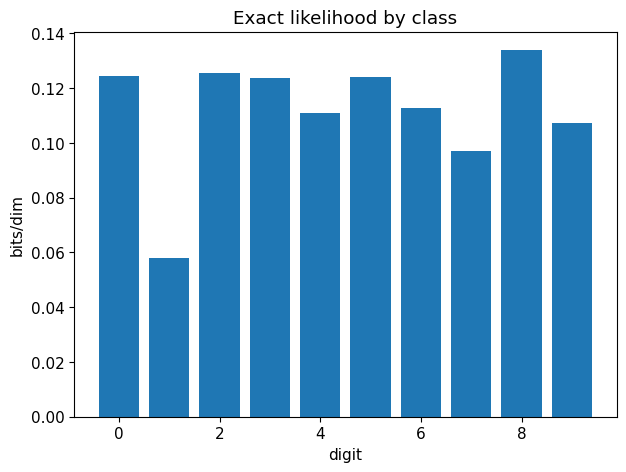

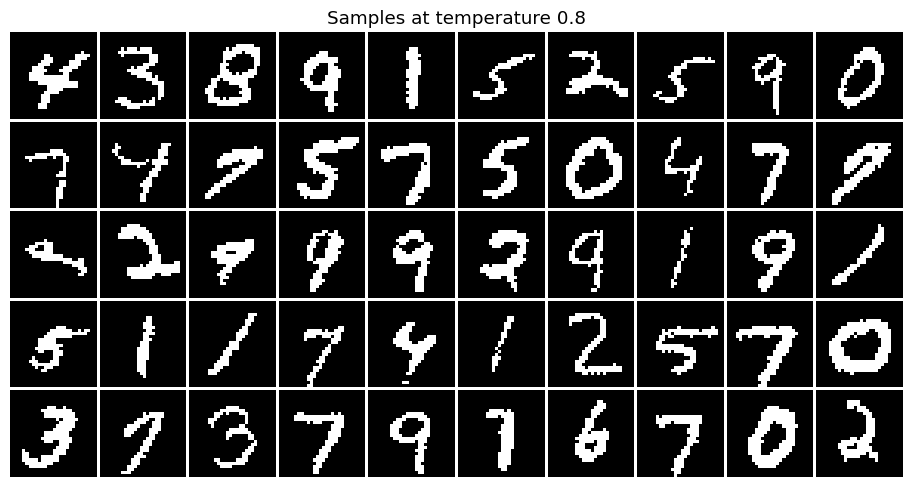

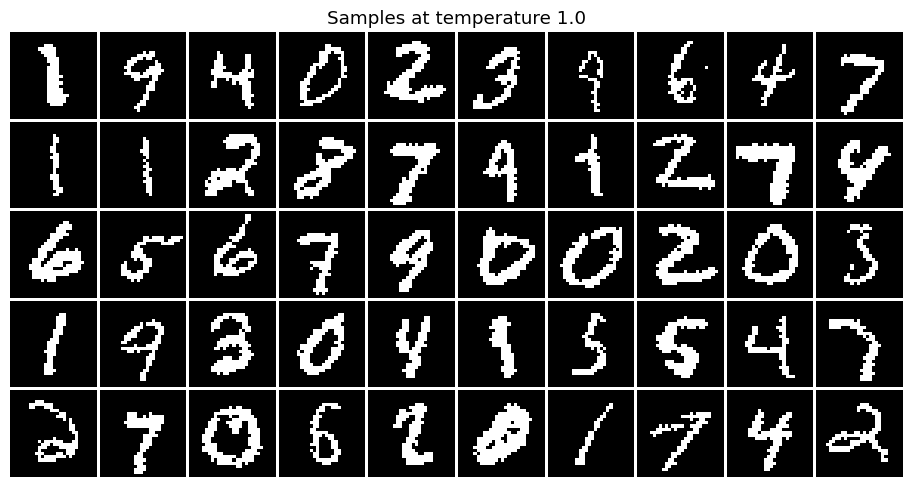

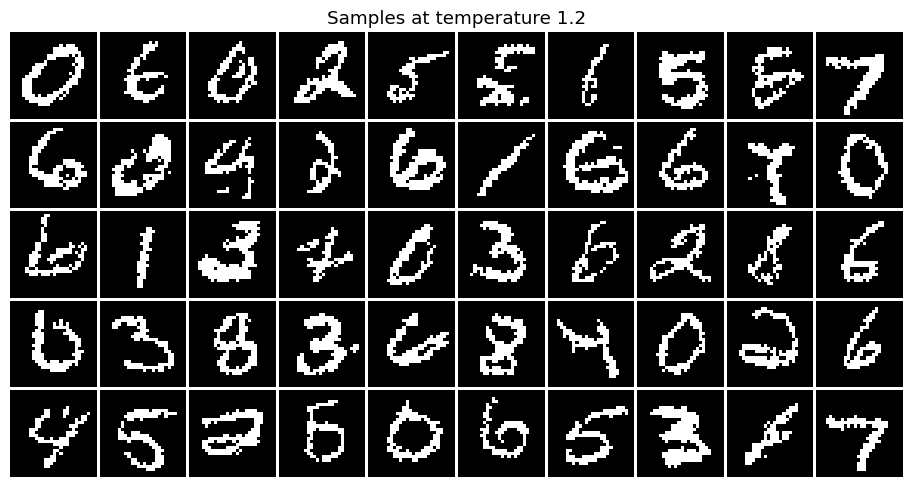

In [10]:
per_class = [[] for _ in range(10)]
with torch.no_grad():
    for images, labels in test_loader:
        binary = (images >= 0.5).float().to(DEVICE)
        inputs, targets = shifted_tokens(binary)
        logits = model(inputs)
        bpd = F.binary_cross_entropy_with_logits(
            logits, targets.float(), reduction="none"
        ).sum(1) / (784 * math.log(2))
        for digit in range(10):
            per_class[digit].append(bpd.cpu()[labels == digit])
means = torch.tensor([torch.cat(parts).mean() for parts in per_class])
plt.bar(range(10), means)
plt.xlabel("digit")
plt.ylabel("bits/dim")
plt.title("Exact likelihood by class")
plt.show()
for temperature in [0.8, 1.0, 1.2]:
    samples, _ = sample(model, 50, temperature)
    show_image_grid(samples, 10, f"Samples at temperature {temperature}")

## 11. What this demonstrates

### Strengths
- exact normalized likelihood;
- flexible density without invertibility constraints;
- global access to the complete preceding prefix;
- parallel teacher-forced training;
- natural prefix completion.

### Costs and limitations
- exact ancestral sampling remains sequential over 784 pixels;
- raster order introduces an arbitrary directional bias;
- $O(L^2)$ training attention is expensive as resolution grows;
- binary MNIST is simpler than 8-bit natural images, which need richer output distributions;
- likelihood captures pixel regularity and is not identical to perceptual quality.


## Homework experiments 

### Mini-experiment 1 — Cache ablation
- **Hypothesis:** Disabling the key/value cache leaves samples unchanged under controlled randomness but increases generation time.
- **Metric/plot:** Compare seconds per image and verify pixelwise agreement for cached and uncached sampling.
- **Controls:** Reuse one checkpoint, seed, temperature, prefix, batch size, and device. Warm up both paths.
- **Interpretation:** A speed difference with matching pixels isolates implementation efficiency rather than modeling quality. 

### Mini-experiment 2 — Reverse raster order
- **Hypothesis:** Reversing order preserves exact likelihood in principle but changes which spatial dependencies are easiest to learn.
- **Metric/plot:** Plot per-class test bpd and matched sample/prefix-completion grids for both orders.
- **Controls:** Match parameter count, optimization budget, dynamic binarization, seed policy, and evaluation set.
- **Interpretation:** Differences expose ordering bias rather than a change to the chain rule. 

### Extensions
- Add class conditioning.
- Use 8-bit categorical tokens instead of binarization.
- Replace full attention with local or axial attention.

## Exit ticket

1. What must remain invariant when future pixels are changed in a causal model?
<details><summary>Self-check</summary>Logits for positions whose prefixes are unchanged must remain equal up to numerical precision.</details>

2. Why is training parallel but exact generation sequential?
<details><summary>Self-check</summary>Teacher forcing supplies every previous token at once. The generation phase must sample each token before it can condition the next.</details>

3. What distribution does prefix completion sample from?
<details><summary>Self-check</summary>It samples the missing suffix from the model conditional on the fixed observed prefix and the chosen raster order.</details>

## References and further reading

- [van den Oord et al., “Pixel Recurrent Neural Networks” (ICML 2016)](https://proceedings.mlr.press/v48/oord16.html): Foundational image-level autoregressive likelihood modeling.
- [Vaswani et al., “Attention Is All You Need” (NeurIPS 2017)](https://proceedings.neurips.cc/paper/7181-attention-is-all-you-need): Introduces the Transformer machinery adapted here with causal masking and caching.